# 01 – Abstandszonen, Kontaktgraphen und Makrozustände

**Team 2 – Makrozustände und Attractor Memory** (Aufgabenblatt §5–8)

Diese Pipeline liest ausschließlich die vorhandenen Team-1-CSVs. Positionen und
die periodische Box werden in Metern verarbeitet, Oberflächenabstände intern in
Metern und in Tabellen zusätzlich in Nanometern ausgegeben. Der Oberflächenabstand
ist `L = ||x_j − x_i|| − 2R`, nicht der Mittelpunktabstand. Für die Team-1-Daten
gilt eine feste Box von 20 µm; sie wird nicht aus den Koordinaten geschätzt.

In [1]:
import sys
from pathlib import Path

PROJECT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from src.contact_graphs import contact_graph, pair_table
from src.pipeline import GRAPH_TYPES, load_team1_data, run_pipeline
from src.plots import save_fig, setup_style

setup_style()
TEAM1_DATA = PROJECT.parent / 'team1_forces' / 'data' / 'processed'
OUT = PROJECT / 'data' / 'processed'
BOX = 20e-6
MIN_DWELL = 5
pd.set_option('display.max_columns', 30)

## Dateninventar und Einheiten

`A_H = 0.5×10⁻²¹ J` und `5×10⁻²¹ J` werden gemäß Team-1-Konvention als
`fatty_acid` beziehungsweise `PMBC` übernommen. Andere Werte bleiben `unknown`.
N=20 und N=50 werden durch die Partikelzahl je Run getrennt.

In [2]:
positions, parameters = load_team1_data(TEAM1_DATA, box=BOX)
inventory = positions.groupby('run_id').agg(
    seed=('seed', 'first'), model_type=('model_type', 'first'),
    material_type=('material_type', 'first'), A_H=('A_H', 'first'),
    salt_mM=('salt_mM', 'first'), R_nm=('R_nm', 'first'),
    n_particles=('particle_id', 'nunique'), n_frames=('time', 'nunique'),
    t_start_s=('time', 'min'), t_end_s=('time', 'max'),
).reset_index()
display(inventory)
assert not positions.empty
assert np.isfinite(positions[['x', 'y']].to_numpy()).all()
n_by_run = inventory.set_index('run_id').n_particles

,run_id,seed,model_type,material_type,A_H,salt_mM,R_nm,n_particles,n_frames,t_start_s,t_end_s
0,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,5.000000e-21,100,500.0,20,1000,0.000005,0.005
1,cl_retarded_A5.0e-21_I100_N20_s1,1,cl_retarded,PMBC,5.000000e-21,100,500.0,20,1000,0.000005,0.005
2,cl_retarded_A5.0e-21_I100_N20_s42,42,cl_retarded,PMBC,5.000000e-21,100,500.0,20,1000,0.000005,0.005
3,cl_retarded_A5.0e-21_I100_N50_s42,42,cl_retarded,PMBC,5.000000e-21,100,500.0,50,1000,0.000005,0.005
4,cl_retarded_A5.0e-22_I100_N20_s0,0,cl_retarded,fatty_acid,5.000000e-22,100,500.0,20,1000,0.000005,0.005
5,cl_retarded_A5.0e-22_I100_N20_s1,1,cl_retarded,fatty_acid,5.000000e-22,100,500.0,20,1000,0.000005,0.005
6,cl_retarded_A5.0e-22_I100_N20_s42,42,cl_retarded,fatty_acid,5.000000e-22,100,500.0,20,1000,0.000005,0.005
7,dlvo_A5.0e-21_I100_N20_s0,0,dlvo_classic,PMBC,5.000000e-21,100,500.0,20,1000,0.000005,0.005
8,dlvo_A5.0e-21_I100_N20_s1,1,dlvo_classic,PMBC,5.000000e-21,100,500.0,20,1000,0.000005,0.005
9,dlvo_A5.0e-21_I100_N20_s42,42,dlvo_classic,PMBC,5.000000e-21,100,500.0,20,1000,0.000005,0.005


## Physikalisch begründeter Zonenkatalog

Die Grenzen werden unverändert aus §6 übernommen. `far_gap` ist nur explorative
räumliche Nähe und keine harte Bindung. Negative L bleiben als Überlappungsdiagnose
sichtbar und fallen nach der wörtlichen Regel unter `hard_contact`.

In [3]:
zone_catalogue = pd.DataFrame([
    ('hard_contact', 'L < 2 nm', 'Core/Hydration; numerisch sensitiv'),
    ('dlvo_zone', '2 ≤ L < 5 nm', 'elektrostatische DLVO-Repulsion möglich'),
    ('near_gap', '5 ≤ L < 10 nm', 'enger Übergangsbereich'),
    ('meso_gap', '10 ≤ L < 30 nm', 'retardierte/materialabhängige Kopplung'),
    ('far_gap', '30 ≤ L < 100 nm', 'nur explorative mesoskalige Nähe'),
    ('separated', 'L ≥ 100 nm', 'keine Standard-Kontaktkante'),
], columns=['Zone', 'Oberflächenabstand', 'Interpretation'])
display(zone_catalogue)

,Zone,Oberflächenabstand,Interpretation
0,hard_contact,L < 2 nm,Core/Hydration; numerisch sensitiv
1,dlvo_zone,2 ≤ L < 5 nm,elektrostatische DLVO-Repulsion möglich
2,near_gap,5 ≤ L < 10 nm,enger Übergangsbereich
3,meso_gap,10 ≤ L < 30 nm,retardierte/materialabhängige Kopplung
4,far_gap,30 ≤ L < 100 nm,nur explorative mesoskalige Nähe
5,separated,L ≥ 100 nm,keine Standard-Kontaktkante


In [4]:
outputs = run_pipeline(TEAM1_DATA, OUT, box=BOX, min_dwell=MIN_DWELL)
pair_zones = outputs['pair_zones']
graph_features = outputs['graph_features']
sequences = outputs['macrostate_sequences']

graph_features['n_particles'] = graph_features.run_id.map(n_by_run).astype(int)
sequences['n_particles'] = sequences.run_id.map(n_by_run).astype(int)
graph_features.to_csv(OUT / 'graph_features.csv', index=False)
sequences.to_csv(OUT / 'macrostate_sequences.csv', index=False)
for name, frame in outputs.items():
    print(f'{name}: {frame.shape[0]} Zeilen, {frame.shape[1]} Spalten')
display(pair_zones.zone.value_counts().rename('Paarzeilen').to_frame())

pair_zones: 545316 Zeilen, 10 Spalten
graph_features: 57000 Zeilen, 17 Spalten
macrostate_sequences: 57000 Zeilen, 18 Spalten


,Paarzeilen
zone,
hard_contact,352483
meso_gap,104033
dlvo_zone,50623
far_gap,33990
near_gap,4187


## Graphbeispiele und Kontaktdefinitionen

Alle Graphen enthalten auch isolierte Knoten. `G_hard` akzeptiert nur
`hard_contact`, `G_near` zusätzlich DLVO- und Near-Zone, `G_meso` zusätzlich
die Meso-Zone bis 30 nm. Daraus folgt nicht, dass mesoskalige Nähe eine Bindung
beweist; der Vergleich ist eine Sensitivitätsanalyse der Zustandsdefinition.

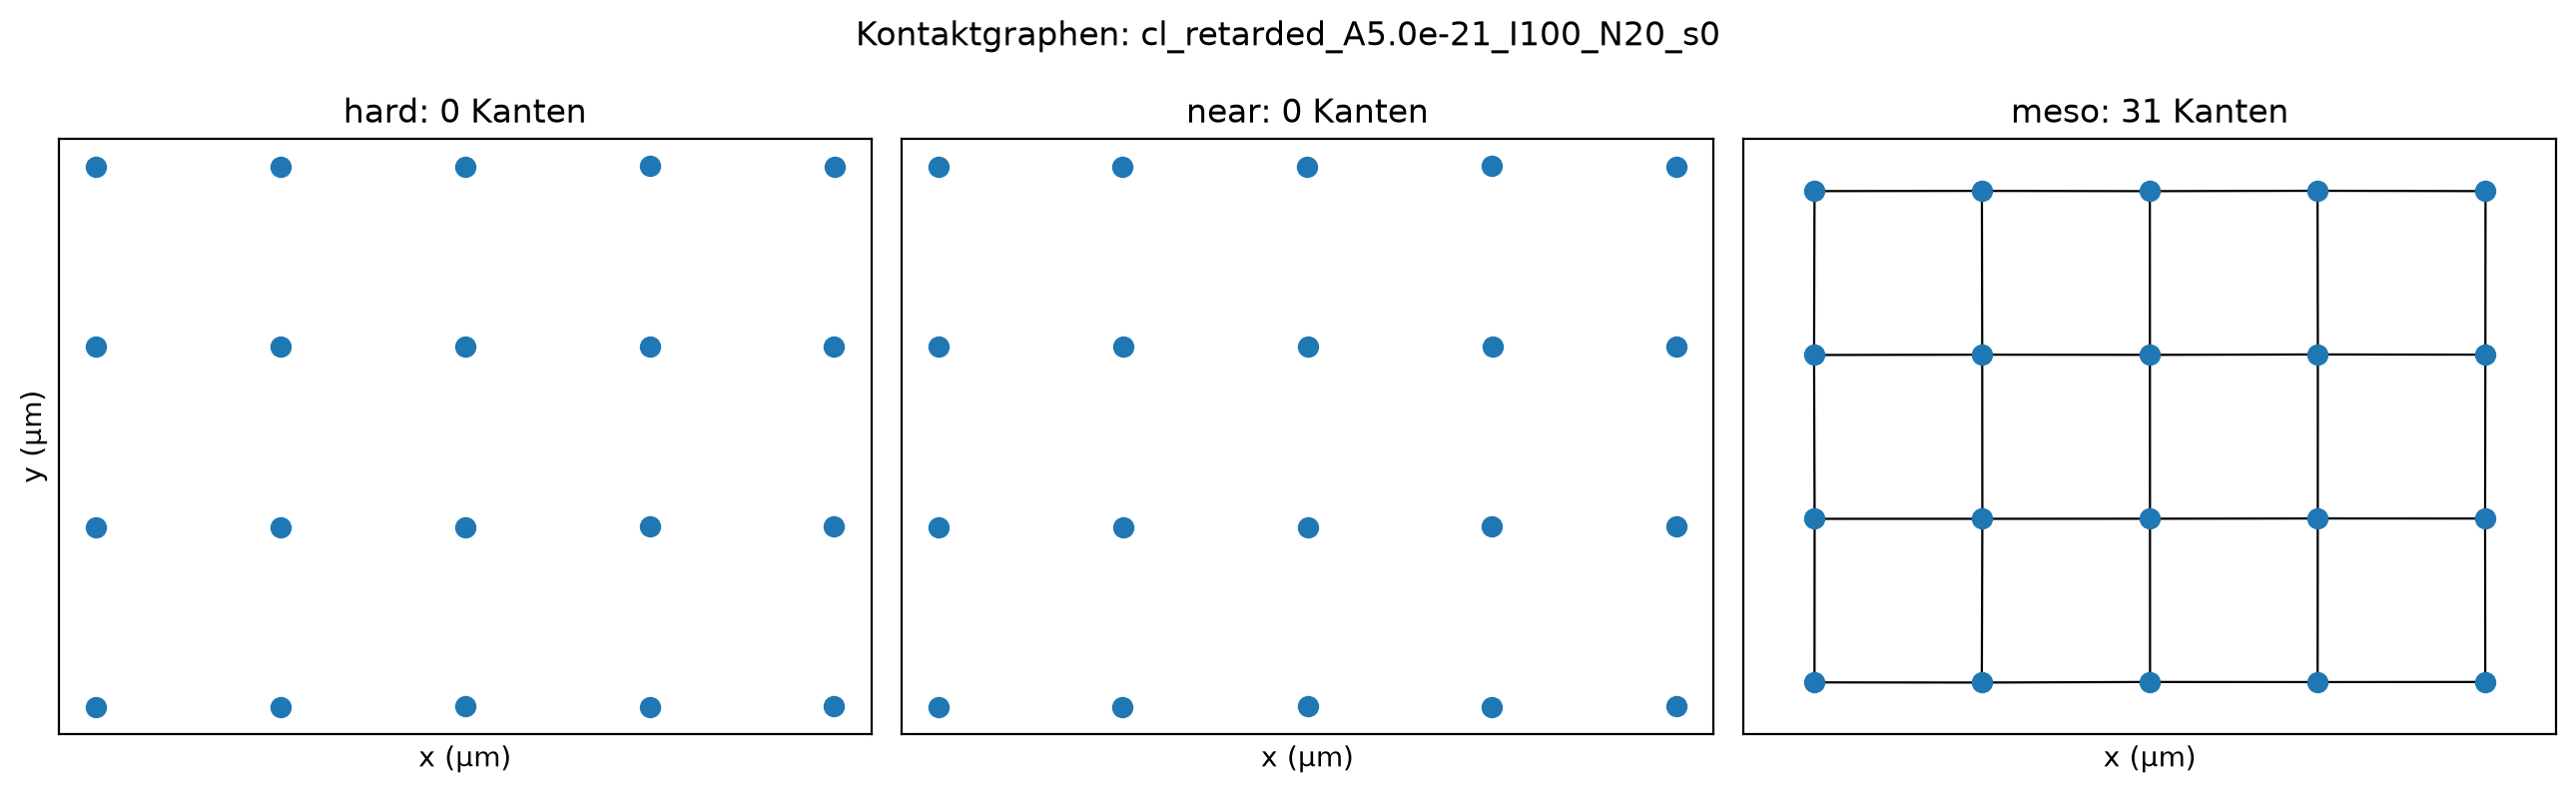

,Label-Übereinstimmung
hard vs near,0.832158
near vs meso,0.809526
hard vs meso,0.687105


In [5]:
example_run_id = inventory[(inventory.n_particles == 20)].sort_values('run_id').run_id.iloc[0]
example_time = positions[positions.run_id == example_run_id].time.min()
frame = positions[(positions.run_id == example_run_id) & (positions.time == example_time)]
frame = frame.sort_values('particle_id')
ids = frame.particle_id.tolist()
xyz = frame[['x', 'y']].to_numpy()
pairs = pair_table(xyz, ids, R=frame.R_nm.iloc[0] * 1e-9, box=BOX)
coordinates = {pid: xy / 1e-6 for pid, xy in zip(ids, xyz)}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, graph_type in zip(axes, GRAPH_TYPES):
    graph = contact_graph(pairs, ids, graph_type=graph_type)
    nx.draw_networkx_nodes(graph, coordinates, node_size=45, ax=ax)
    nx.draw_networkx_edges(graph, coordinates, width=0.8, ax=ax)
    ax.set_title(f'{graph_type}: {graph.number_of_edges()} Kanten')
    ax.set_xlabel('x (µm)')
    ax.grid(False)
axes[0].set_ylabel('y (µm)')
fig.suptitle(f'Kontaktgraphen: {example_run_id}')
fig.tight_layout()
plt.show()

label_pivot = sequences.pivot(index=['run_id', 'time'], columns='graph_type', values='macrostate_raw')
agreement = pd.Series({
    f'{left} vs {right}': (label_pivot[left] == label_pivot[right]).mean()
    for left, right in [('hard', 'near'), ('near', 'meso'), ('hard', 'meso')]
}, name='Label-Übereinstimmung')
display(agreement.to_frame())

## Abbildung 2 – Clustergrößenverteilung nach Modell und Material

Gezeigt wird die Verteilung der **größten zusammenhängenden Komponente** im
Meso-Graphen für die vergleichbaren N=20-Runs. Der N=50-Lauf wird nicht in
dieselbe Statistik gemischt.

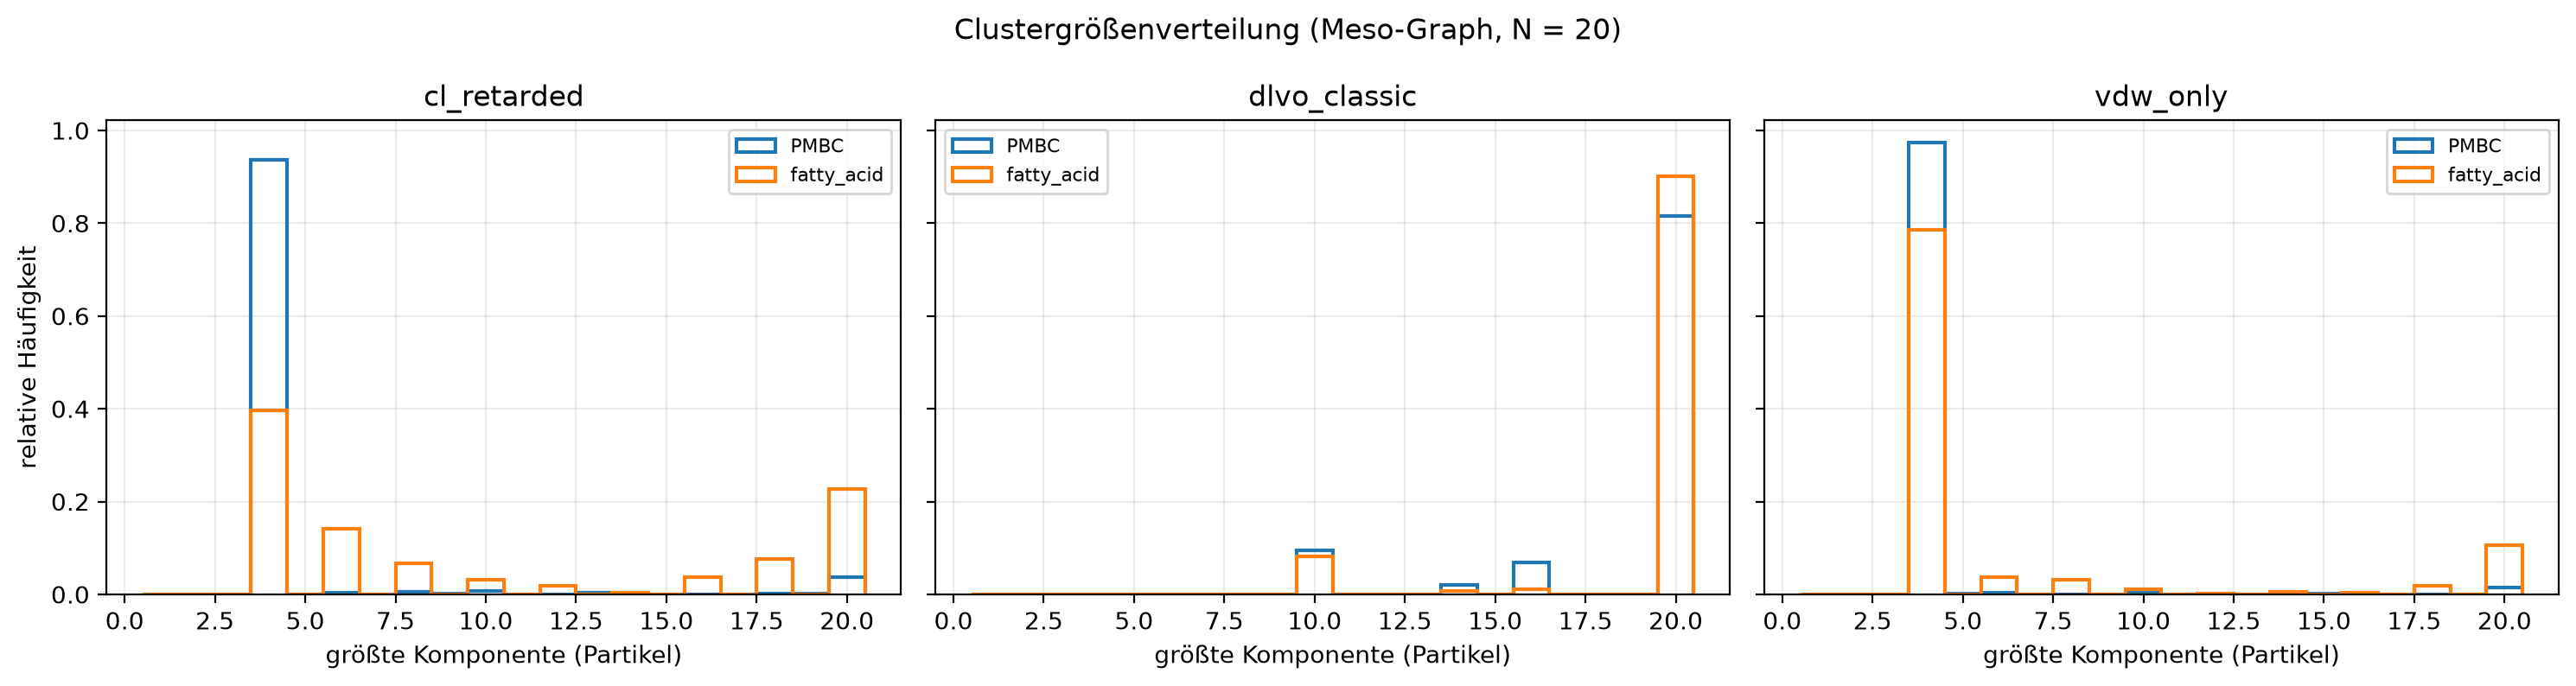

,model_type,material_type,macrostate_raw,relative Häufigkeit
0,cl_retarded,PMBC,tetra_like,0.936667
1,cl_retarded,PMBC,large_cluster,0.063333
2,cl_retarded,fatty_acid,large_cluster,0.602667
3,cl_retarded,fatty_acid,tetra_like,0.393333
4,cl_retarded,fatty_acid,loose_four_cluster,0.004000
5,dlvo_classic,PMBC,large_cluster,1.000000
6,dlvo_classic,fatty_acid,large_cluster,1.000000
7,vdw_only,PMBC,tetra_like,0.973000
8,vdw_only,PMBC,large_cluster,0.027000
9,vdw_only,fatty_acid,tetra_like,0.781333


In [6]:
fair = graph_features[(graph_features.n_particles == 20) & (graph_features.graph_type == 'meso')]
models = sorted(fair.model_type.unique())
materials = sorted(fair.material_type.unique())
colors = {'fatty_acid': 'tab:orange', 'PMBC': 'tab:blue'}
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4), sharey=True, squeeze=False)
for ax, model in zip(axes[0], models):
    subset_model = fair[fair.model_type == model]
    maximum = int(subset_model.largest_cluster.max())
    bins = np.arange(0.5, maximum + 1.5, 1)
    for material in materials:
        values = subset_model[subset_model.material_type == material].largest_cluster.to_numpy()
        if len(values):
            ax.hist(values, bins=bins, weights=np.ones(len(values)) / len(values),
                    histtype='step', linewidth=1.5, label=material,
                    color=colors.get(material))
    ax.set_title(model)
    ax.set_xlabel('größte Komponente (Partikel)')
    ax.legend(fontsize=8)
axes[0][0].set_ylabel('relative Häufigkeit')
fig.suptitle('Clustergrößenverteilung (Meso-Graph, N = 20)')
fig.tight_layout()
save_fig(fig, '02_clustergroessen_modelle')
plt.show()

state_frequency = (sequences[(sequences.n_particles == 20) & (sequences.graph_type == 'meso')]
    .groupby(['model_type', 'material_type']).macrostate_raw.value_counts(normalize=True)
    .rename('relative Häufigkeit').reset_index())
display(state_frequency)

### Methodisches Zwischenfazit

Die Labels beschreiben zunächst nur Snapshots unter drei Kontaktdefinitionen.
Persistenz, Rückkehr und Jitter-Robustheit werden in den nächsten Notebooks
geprüft. Die vorgeclusterten Starts erlauben Aussagen über Beständigkeit,
nicht über spontane Clusterentstehung aus einer verdünnten Phase.